# Firing Rates and Population Synchrony

This tutorial covers the population-level measures of `braintools.analysis`, applied to synthetic data whose ground truth is known. Spike-matrix measures live in `braintools.analysis.spike` and measures of continuous signals in `braintools.analysis.population`:

| Function | Input | Output |
|---|---|---|
| `spike.firing_rate(spikes, width, dt)` | spike matrix `(T, N)` | population rate in Hz, smoothed with a box of width `width` |
| `spike.cross_correlation(spikes, bin, dt)` | spike matrix | Wang-Buzsaki coherence $\kappa$, averaged over pairs |
| `population.voltage_fluctuation(potentials)` | membrane potentials `(T, N)` | Golomb synchrony $\chi^2 \in [0, 1]$ |
| `population.functional_connectivity(activities)` | signals `(T, N)` | `(N, N)` Pearson correlation matrix |
| `population.functional_connectivity_dynamics(activities, window_size, step_size)` | signals | correlation between sliding-window FC matrices |

**Time units.** Pass times as `brainunit` quantities (`10 * u.ms`) and they are converted. Plain numbers follow each function's documented convention: `firing_rate` treats them as seconds, `cross_correlation` as milliseconds. Using quantities avoids having to remember which.

## 1. Setup and Synthetic Populations

In [1]:
import brainunit as u
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

import braintools.analysis as ba

rng = np.random.default_rng(0)
dt = 0.1 * u.ms
T = 20_000  # 2 s
t_ms = np.arange(T) * 0.1

Three groups of 20 neurons, all firing at about 10 Hz on average:

- **independent**: homogeneous Poisson trains;
- **common input**: each neuron's rate is modulated by the same slow signal, so the trains are correlated on a 50 ms time scale but not precisely synchronized;
- **synchronous events**: background Poisson spikes plus 20 population events in which each neuron fires with probability 0.5 within about 1 ms.

In [2]:
def poisson(rate_hz, shape):
    return (rng.random(shape) < rate_hz * 1e-4).astype(float)  # dt = 0.1 ms


independent = poisson(10.0, (T, 20))

shared = np.convolve(rng.normal(size=T), np.ones(500) / np.sqrt(500), mode="same")  # ~50 ms correlated
modulation = np.exp(1.2 * shared)
rate = 10.0 * modulation / modulation.mean()  # mean exactly 10 Hz
common = (rng.random((T, 20)) < (rate * 1e-4)[:, None]).astype(float)

events = rng.choice(np.arange(500, T - 500), 20, replace=False)
synchronous = poisson(5.0, (T, 20))
for e in events:
    fire = rng.random(20) < 0.5
    synchronous[e + rng.integers(-10, 11, fire.sum()), np.flatnonzero(fire)] = 1

spikes = np.concatenate([independent, common, synchronous], axis=1)
groups = {"independent": slice(0, 20), "common input": slice(20, 40), "synchronous": slice(40, 60)}
for name, g in groups.items():
    print(f"{name:13s} mean rate {spikes[:, g].sum() / 20 / 2.0:5.1f} Hz")

independent   mean rate  10.4 Hz
common input  mean rate   9.7 Hz
synchronous   mean rate  10.4 Hz


## 2. Raster Plot and Population Rate

For a raster, `np.nonzero` on the spike matrix gives the time step and neuron index of every spike (the deprecated `braintools.metric.raster_plot` did the same; `braintools.spike.SpikeTrains` replaces it). `firing_rate` averages the spike matrix over neurons and smooths it with a box of width `width`, giving the population rate in Hz; a wider box trades temporal detail for less noise.

1219 spikes, neuron indices 0..59


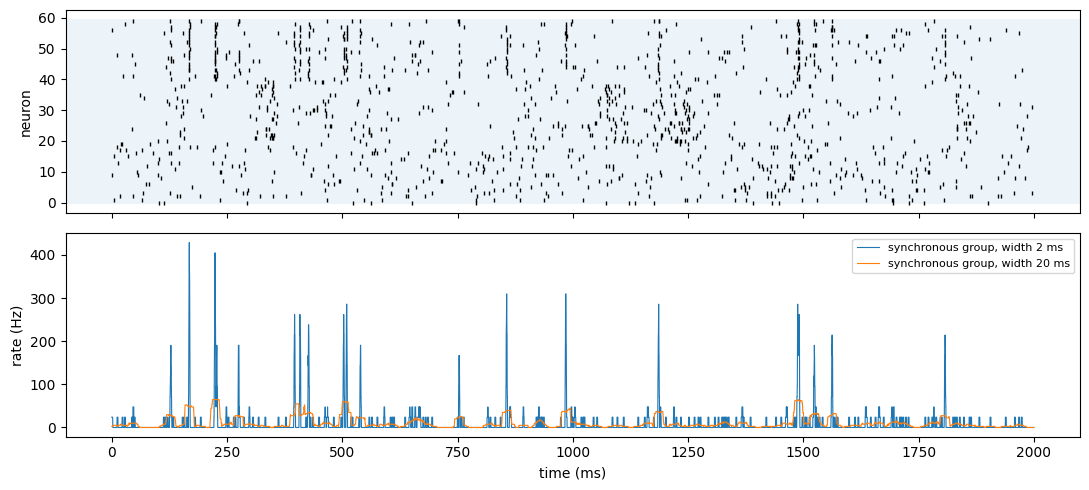

independent group: time-averaged rate 10.34 Hz (spike count gives 10.38 Hz)
same result with seconds: 10.343284606933594


In [3]:
t_idx, idx = np.nonzero(spikes)  # time step and neuron of every spike
times = t_ms[t_idx]
print(f"{len(times)} spikes, neuron indices {int(idx.min())}..{int(idx.max())}")

fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
axes[0].plot(times, idx, "|", ms=3, color="k")
for name, g in groups.items():
    axes[0].axhspan(g.start - 0.5, g.stop - 0.5, alpha=0.08)
axes[0].set_ylabel("neuron")
for width in [2 * u.ms, 20 * u.ms]:
    r = ba.spike.firing_rate(spikes[:, 40:60], width, dt)
    axes[1].plot(t_ms, r, lw=0.8, label=f"synchronous group, width {width}")
axes[1].set_ylabel("rate (Hz)")
axes[1].set_xlabel("time (ms)")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

r = ba.spike.firing_rate(spikes[:, :20], 20 * u.ms, dt)
print(f"independent group: time-averaged rate {float(r.mean()):.2f} Hz (spike count gives "
      f"{spikes[:, :20].sum() / 20 / 2.0:.2f} Hz)")
print("same result with seconds:", float(ba.spike.firing_rate(spikes[:, :20], 0.02 * u.second, 1e-4 * u.second).mean()))

## 3. Spike-Count Coherence $\kappa$ (`cross_correlation`)

The spike trains are cut into bins of width `bin`; $X_i(l) \in \{0, 1\}$ marks whether neuron $i$ fired in bin $l$, and for each pair

$$\kappa_{ij} = \frac{\sum_l X_i(l) X_j(l)}{\sqrt{\sum_l X_i(l) \sum_l X_j(l)}},$$

averaged over all pairs (Wang & Buzsaki, 1996). $\kappa$ is **not corrected for chance**: for independent trains, $\kappa$ is roughly the probability that a bin contains a spike, so it grows with firing rate and bin width. Always compare against a chance level, for example obtained by circularly shifting each train by a random amount, which keeps rates and spike patterns but destroys their alignment.

In [4]:
def shuffled(s):
    return np.stack([np.roll(s[:, i], rng.integers(T)) for i in range(s.shape[1])], axis=1)


print(f"{'group':13s} {'kappa':>7s} {'shuffled':>9s}   (bin = 5 ms)")
for name, g in groups.items():
    k = float(ba.spike.cross_correlation(spikes[:, g], 5 * u.ms, dt))
    k0 = float(ba.spike.cross_correlation(shuffled(spikes[:, g]), 5 * u.ms, dt))
    print(f"{name:13s} {k:7.3f} {k0:9.3f}")

print("\nindependent Poisson trains: kappa grows with rate")
for rate_hz in [5, 20, 80]:
    k = float(ba.spike.cross_correlation(poisson(rate_hz, (T, 20)), 5 * u.ms, dt))
    print(f"  {rate_hz:3d} Hz: kappa {k:.3f}, P(spike in a 5 ms bin) = {1 - np.exp(-rate_hz * 0.005):.3f}")

group           kappa  shuffled   (bin = 5 ms)


independent     0.056     0.053
common input    0.103     0.043
synchronous     0.272     0.045

independent Poisson trains: kappa grows with rate


    5 Hz: kappa 0.023, P(spike in a 5 ms bin) = 0.025
   20 Hz: kappa 0.095, P(spike in a 5 ms bin) = 0.095
   80 Hz: kappa 0.330, P(spike in a 5 ms bin) = 0.330


The synchronous group stands far above its shuffled level, and the common-input group is above it as well. The independent group is at chance, whose value depends on the rate. A raw $\kappa$ is only interpretable next to its chance level.

## 4. Membrane-Potential Synchrony $\chi^2$ (`voltage_fluctuation`)

For membrane potentials $V_i(t)$ and their population average $\bar V(t)$, Golomb's measure is

$$\chi^2 = \frac{\operatorname{Var}_t[\bar V]}{\frac1N\sum_i \operatorname{Var}_t[V_i]} \in [0, 1],$$

equal to 1 for identical traces and about $1/N$ for independent ones. If every trace is a shared signal with variance fraction $c$ plus independent noise, $\chi^2 \approx c + (1 - c)/N$.

In [5]:
N = 40
n_t = 5000
common_v = rng.normal(size=n_t)
print(f"{'shared fraction c':>18s} {'chi^2':>7s} {'c + (1-c)/N':>12s}")
for c in [0.0, 0.2, 0.5, 0.9, 1.0]:
    V = np.sqrt(c) * common_v[:, None] + np.sqrt(1 - c) * rng.normal(size=(n_t, N))
    print(f"{c:18.1f} {float(ba.population.voltage_fluctuation(V)):7.3f} {c + (1 - c) / N:12.3f}")

 shared fraction c   chi^2  c + (1-c)/N


               0.0   0.025        0.025


               0.2   0.215        0.220
               0.5   0.508        0.512
               0.9   0.901        0.902


               1.0   1.000        1.000


## 5. Functional Connectivity

`functional_connectivity` is the Pearson correlation matrix of the columns of its input (`np.corrcoef` of the transposed array). For spikes, bin them first; the bin width sets the time scale of the correlations you detect. With 50 ms bins both correlated groups stand out from the independent one, which sits near zero.

matches np.corrcoef: True


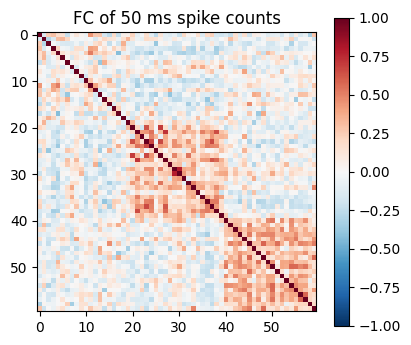

independent   mean within-group correlation +0.038
common input  mean within-group correlation +0.259
synchronous   mean within-group correlation +0.286


In [6]:
counts = spikes.reshape(-1, 500, 60).sum(axis=1)  # 50 ms bins
fc = np.asarray(ba.population.functional_connectivity(counts))
print("matches np.corrcoef:", np.allclose(fc, np.corrcoef(counts.T), atol=1e-5))

fig, ax = plt.subplots(figsize=(4.5, 4))
im = ax.imshow(fc, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_title("FC of 50 ms spike counts")
fig.colorbar(im, ax=ax)
plt.show()

off = ~np.eye(20, dtype=bool)
for name, g in groups.items():
    print(f"{name:13s} mean within-group correlation {fc[g, g][off].mean():+.3f}")

`functional_connectivity_dynamics` slides a window along the signals, computes an FC matrix in each window, and correlates the FC matrices with each other. Blocks in the resulting matrix are periods with a stable connectivity pattern. Below, 8 signals switch halfway from one correlation structure (channels 0-3 coupled) to another (channels 4-7 coupled).

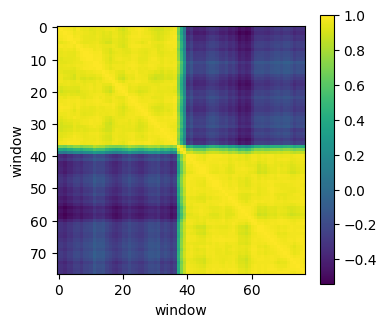

77 windows; mean FCD within halves 0.96, between halves -0.28


In [7]:
n_t = 4000
x = rng.normal(size=(n_t, 8))
drive = rng.normal(size=n_t)
x[: n_t // 2, :4] += 1.5 * drive[: n_t // 2, None]
x[n_t // 2:, 4:] += 1.5 * drive[n_t // 2:, None]

fcd = np.asarray(ba.population.functional_connectivity_dynamics(x, window_size=200, step_size=50))
fig, ax = plt.subplots(figsize=(4, 3.5))
im = ax.imshow(fcd, cmap="viridis")
ax.set_xlabel("window")
ax.set_ylabel("window")
fig.colorbar(im, ax=ax)
plt.show()
h = fcd.shape[0] // 2
print(f"{fcd.shape[0]} windows; mean FCD within halves {np.mean([fcd[:h - 2, :h - 2].mean(), fcd[h + 2:, h + 2:].mean()]):.2f}, "
      f"between halves {fcd[:h - 2, h + 2:].mean():.2f}")

## Summary

- A raster (`np.nonzero` on the spike matrix) and `firing_rate` describe activity; pass times as quantities so `firing_rate` returns Hz unambiguously.
- $\kappa$ (`cross_correlation`) is not chance-corrected and grows with rate and bin width; compare with shuffled data.
- `voltage_fluctuation` returns Golomb's $\chi^2 \in [0, 1]$: about $1/N$ for independent and 1 for identical traces.
- `functional_connectivity` is the correlation matrix of binned activity; the bin width selects the time scale. `functional_connectivity_dynamics` shows when that structure changes.